<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap09/9_3_Ensembling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Combine multiple models 

## Ensembling

<mark>Another approach to reducing the generalization gap between training and test data is
to build several models and average their predictions. A group of such models is known as an ensemble.</mark> 

This technique reliably <mark>improves test performance at the cost of training and storing multiple models and performing inference multiple times</mark>.

The models can be combined by taking the <mark>mean of the outputs (for regression problems) or the mean of the pre-softmax activations</mark> (for classification problems). 

The assumption is that model errors are independent and will cancel out. Alternatively, we can take the median of the outputs (for regression problems) or the most frequent predicted class (for classification problems) to make the predictions more robust.

<mark>One way to train different models is just to use different random initializations</mark>. This may help in regions of input space far from the training data. 

Here, the fitted function is relatively unconstrained, and different models may produce different predictions, so the average of several models may generalize better than any single model.

<mark>A second approach is to generate several different datasets by re-sampling the training data with replacement and training a different model from each</mark>. 

This is known as <mark>bootstrap aggregating or bagging for short</mark>. 

It has the effect of smoothing out the data; if a data point is not present in one training set, the model will interpolate from nearby points; hence, if that point was an outlier, the fitted function will be more moderate in this region. 

Other approaches include training models with different hyperparameters or training completely different families of models.

<img src="assets/Chap09/RegEnsemble.svg" width="100%" style="filter:invert(1)">

Ensemble methods. a) Fitting a single model (gray curve) to the
entire dataset (orange points). b–e) Four models created by re-sampling the data
with replacement (bagging) four times (size of orange point indicates number of
times the data point was re-sampled). f) When we average the predictions of this
ensemble, the result (cyan curve) is smoother than the result from panel (a) for
the full dataset (gray curve) and will probably generalize better.

---

This notebook investigates how ensembling can improve the performance of models. We'll work with the simplified neural network model (figure 8.4 of book) which we can fit in closed form, and so we can eliminate any errors due to not finding the global maximum.


In [14]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
# Define seed to get same results each time
np.random.seed(1)

plt.style.use('dark_background')

In [15]:
# The true function that we are trying to estimate, defined on [0,1]
def true_function(x):
    y = np.exp(np.sin(x*(2*3.1413)))
    return y

In [16]:
# Generate some data points with or without noise
def generate_data(n_data, sigma_y=0.3):
    # Generate x values quasi uniformly
    x = np.ones(n_data)
    for i in range(n_data):
        x[i] = np.random.uniform(i/n_data, (i+1)/n_data, 1)

    # y value from running through function and adding noise
    y = np.ones(n_data)
    for i in range(n_data):
        y[i] = true_function(x[i])
        y[i] += np.random.normal(0, sigma_y, 1)
    return x,y

In [17]:
# Draw the fitted function, together with uncertainty used to generate points
def plot_function(x_func, y_func, x_data=None,y_data=None, x_model = None, y_model =None, sigma_func = None, sigma_model=None):

    fig,ax = plt.subplots()
    ax.plot(x_func, y_func, 'k-')
    if sigma_func is not None:
      ax.fill_between(x_func, y_func-2*sigma_func, y_func+2*sigma_func, color='lightgray')

    if x_data is not None:
        ax.plot(x_data, y_data, 'o', color='#d18362')

    if x_model is not None:
        ax.plot(x_model, y_model, '-', color='#7fe7de')

    if sigma_model is not None:
      ax.fill_between(x_model, y_model-2*sigma_model, y_model+2*sigma_model, color='lightgray')

    ax.set_xlim(0,1)
    ax.set_xlabel('Input, $x$')
    ax.set_ylabel('Output, $y$')
    plt.show()

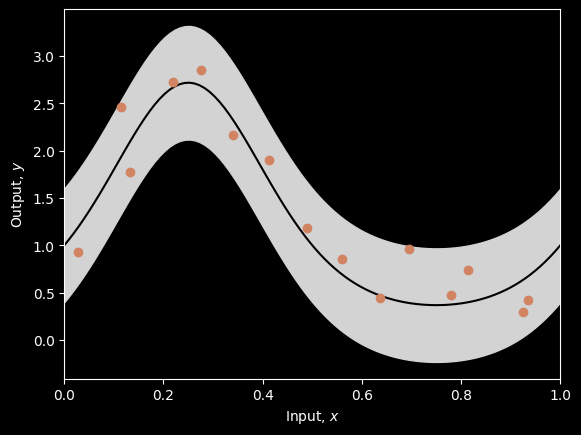

In [18]:
# Generate true function
x_func = np.linspace(0, 1.0, 100)
y_func = true_function(x_func);

# Generate some data points
np.random.seed(1)
sigma_func = 0.3
n_data = 15
x_data,y_data = generate_data(n_data, sigma_func)

# Plot the function, data and uncertainty
plot_function(x_func, y_func, x_data, y_data, sigma_func=sigma_func)

In [19]:
# Define model -- beta is a scalar and omega has size n_hidden,1
def network(x, beta, omega):
    # Retrieve number of hidden units
    n_hidden = omega.shape[0]

    y = np.zeros_like(x)
    for c_hidden in range(n_hidden):
        # Evaluate activations based on shifted lines (figure 8.4b-d)
        line_vals =  x  - c_hidden/n_hidden
        h =  line_vals * (line_vals > 0)
        # Weight activations by omega parameters and sum
        y = y + omega[c_hidden] * h
    # Add bias, beta
    y = y + beta

    return y

In [20]:
# This fits the n_hidden+1 parameters (see fig 8.4a) in closed form.
# If you have studied linear algebra, then you will know it is a least
# squares solution of the form (A^TA)^-1A^Tb.  If you don't recognize that,
# then just take it on trust that this gives you the best possible solution.
def fit_model_closed_form(x,y,n_hidden):
  n_data = len(x)
  A = np.ones((n_data, n_hidden+1))
  for i in range(n_data):
      for j in range(1,n_hidden+1):
          # Compute preactivation
          A[i,j] = x[i]-(j-1)/n_hidden
          # Apply the ReLU function
          if A[i,j] < 0:
              A[i,j] = 0;

  # Add a tiny bit of regularization
  reg_value = 0.00001
  regMat = reg_value * np.identity(n_hidden+1)
  regMat[0,0] = 0

  ATA = np.matmul(np.transpose(A), A) +regMat
  ATAInv = np.linalg.inv(ATA)
  ATAInvAT = np.matmul(ATAInv, np.transpose(A))
  beta_omega = np.matmul(ATAInvAT,y)
  beta = beta_omega[0]
  omega = beta_omega[1:]

  return beta, omega

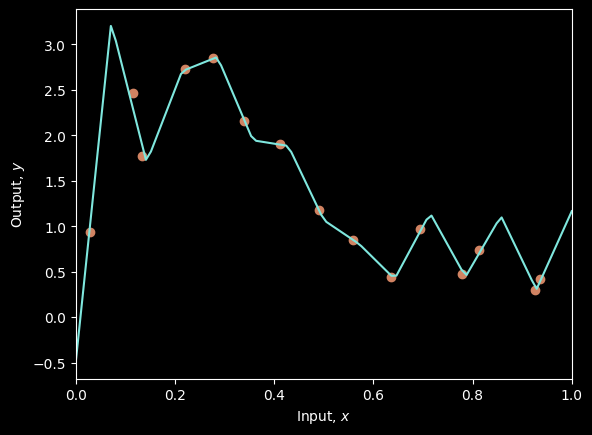

Mean square error = 0.195


In [21]:
# Closed form solution
beta, omega = fit_model_closed_form(x_data,y_data,n_hidden=14)

# Get prediction for model across graph range
x_model = np.linspace(0,1,100);
y_model = network(x_model, beta, omega)

# Draw the function and the model
plot_function(x_func, y_func, x_data,y_data, x_model, y_model)

# Compute the mean squared error between the fitted model (cyan) and the true curve (black)
mean_sq_error = np.mean((y_model-y_func) * (y_model-y_func))
print(f"Mean square error = {mean_sq_error:3.3f}")

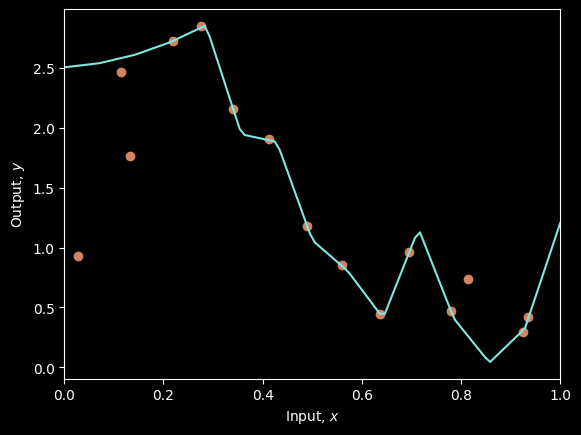

Mean square error = 0.222


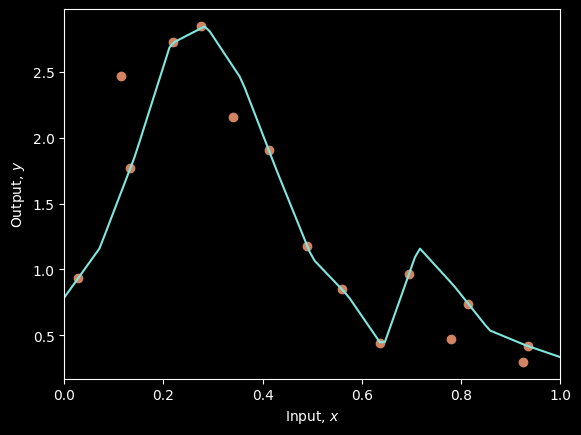

Mean square error = 0.098


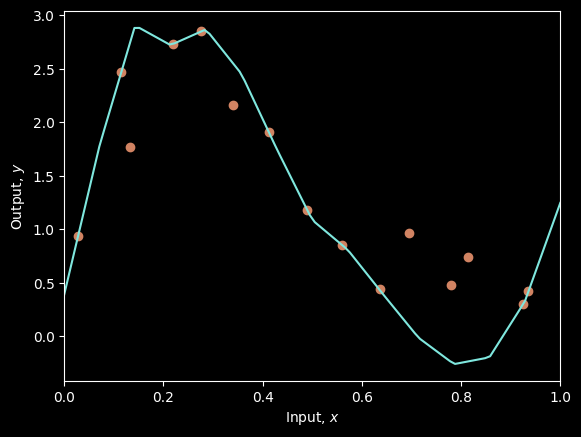

Mean square error = 0.120


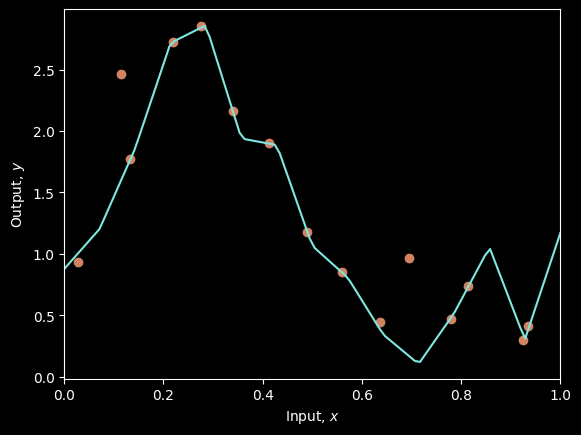

Mean square error = 0.048


In [22]:
# Now let's resample the data with replacement four times.
n_model = 4
# Array to store the prediction from all of our models
all_y_model = np.zeros((n_model, len(y_model)))

# For each model
for c_model in range(n_model):
    resampled_indices = np.random.choice(np.arange(0,n_data,1), size=n_data, replace=True)

    # Extract the resampled x and y data
    x_data_resampled = x_data[resampled_indices]
    y_data_resampled = y_data[resampled_indices]

    # Fit the model
    beta, omega = fit_model_closed_form(x_data_resampled,y_data_resampled,n_hidden=14)

    # Run the model
    y_model_resampled = network(x_model, beta, omega)

    # Store the results
    all_y_model[c_model,:] = y_model_resampled

    # Draw the function and the model
    plot_function(x_func, y_func, x_data,y_data, x_model, y_model_resampled)

    # Compute the mean squared error between the fitted model (cyan) and the true curve (black)
    mean_sq_error = np.mean((y_model_resampled-y_func) * (y_model_resampled-y_func))
    print(f"Mean square error = {mean_sq_error:3.3f}")

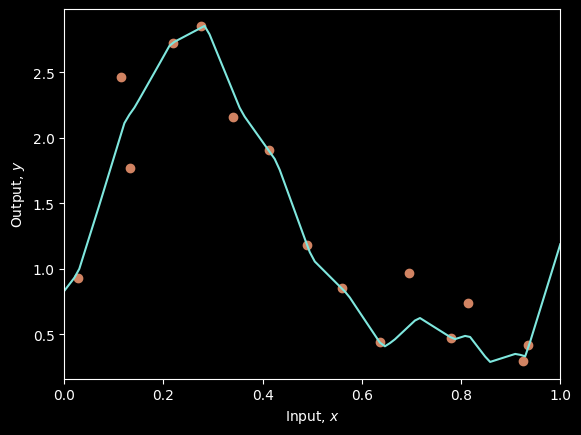

Mean square error = 0.020


In [23]:
y_model_median = np.median(all_y_model, axis=0)

# Draw the function and the model
plot_function(x_func, y_func, x_data,y_data, x_model, y_model_median)

# Compute the mean squared error between the fitted model (cyan) and the true curve (black)
mean_sq_error = np.mean((y_model_median-y_func) * (y_model_median-y_func))
print(f"Mean square error = {mean_sq_error:3.3f}")

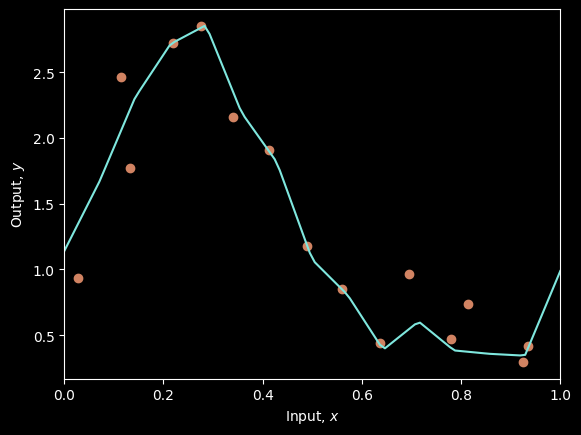

Mean square error = 0.018


In [24]:
y_model_mean = np.mean(all_y_model, axis=0)

# Draw the function and the model
plot_function(x_func, y_func, x_data,y_data, x_model, y_model_mean)

# Compute the mean squared error between the fitted model (cyan) and the true curve (black)
mean_sq_error = np.mean((y_model_mean-y_func) * (y_model_mean-y_func))
print(f"Mean square error = {mean_sq_error:3.3f}")

You should see that both the median and mean models are better than any of the individual models. We have improved our performance at the cost of four times as much training time, storage, and inference time.


## Dropout

Dropout clamps a random subset (typically 50%) of hidden units to zero at each iteration
of SGD. 

This makes the network less dependent on any given hidden unit and
encourages the weights to have smaller magnitudes so that the change in the function
due to the presence or absence of any specific hidden unit is reduced.

This technique has the positive benefit that it can eliminate undesirable “kinks” in
the function that are far from the training data and don’t affect the loss. 

For example, consider three hidden units that become active sequentially as we move along the curve
(figure 9.9a). 

The first hidden unit causes a large increase in the slope. A second hidden unit decreases the slope, so the function goes back down. Finally, the third unit cancels out this decrease and returns the curve to its original trajectory. These three units
conspire to make an undesirable local change in the function. This will not change the training loss but is unlikely to generalize well.

When several units conspire in this way, eliminating one (as would happen in dropout)
causes a considerable change to the output function in the half-space where that unit
was active (figure 9.9b). A subsequent gradient descent step will attempt to compensate
for the change that this induces, and such dependencies will be eliminated over time.

The overall effect is that large unnecessary changes between training data points are
gradually removed even though they contribute nothing to the loss (figure 9.9).

At test time, we can run the network as usual with all the hidden units active;
however, the network now has more hidden units than it was trained with at any given
iteration, so we multiply the weights by one minus the dropout probability to compensate.
This is known as the weight scaling inference rule. 

A different approach to inference is to use Monte Carlo dropout, in which we run the network multiple times with different
random subsets of units clamped to zero (as in training) and combine the results. This
is closely related to ensembling in that every random version of the network is a different
model; however, we do not have to train or store multiple networks here.

<img src="assets/Chap09/RegDropoutNetwork.svg" width="100%" style="filter:invert(1)">

Dropout. a) Original network. b–d) At each training iteration, a
random subset of hidden units is clamped to zero (gray nodes). The result is
that the incoming and outgoing weights from these units have no effect, so we are
training with a slightly different network each time.

<img src="assets/Chap09/RegDropout.svg" width="100%" style="filter:invert(1)">

Dropout mechanism. a) An undesirable kink in the curve is caused
by a sequential increase in the slope, decrease in the slope (at circled joint), and
then another increase to return the curve to its original trajectory. Here we are
using full-batch gradient descent, and the model (from figure 8.4) fits the data
as well as possible, so further training won’t remove the kink. b) Consider what
happens if we remove the eighth hidden unit that produced the circled joint in
panel (a), as might happen using dropout. Without the decrease in the slope,
the right-hand side of the function takes an upwards trajectory, and a subsequent
gradient descent step will aim to compensate for this change. c) Curve after 2000
iterations of (i) randomly removing one of the three hidden units that cause the
kink and (ii) performing a gradient descent step. The kink does not affect the loss
but is nonetheless removed by this approximation of the dropout mechanism.



In [ ]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Linear(10, 64),
    nn.ReLU(),
    nn.Dropout(p=0.5),  # Each activation has a 50% chance of being zeroed
    nn.Linear(64, 1)
)

model.train()           # Dropout ON
predictions = model(torch.randn(8, 10))

model.eval()            # Dropout OFF
with torch.no_grad():
    predictions = model(torch.randn(8, 10))

During training, it randomly zeros activations, not weights, with a new mask each forward pass. 

Surviving values are multiplied by `1 / (1 - p)`—so with `p=0.5`, they double. This preserves each activation's expected value.

During evaluation, it passes the input through unchanged. `torch.no_grad()` alone does not turn dropout off; call `model.eval()`